In [7]:
from math import *
import numpy as np
import matplotlib.pyplot as plt

def g_accel(r: np.ndarray, G: float = 6.67348e-11, M: float = 1.989e30) -> np.ndarray:
    """
    Gravitational acceleration of a body at position r with sun fixed at the origin
    r: current position vector (numpy array)
    Returns a = -GM r / |r|^3
    """
    return -G * M * r / np.linalg.norm(r)**3

def next_r(r_k: np.ndarray, v_k: np.ndarray, dt: float) -> np.ndarray:
    """
    Velocity Verlet position update: r_(k+1) = r_k + v_k dt + 1/2a(r_k) dt^2
    r_k: Current position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    dt: Time step for the simulation, the smaller, the more accurate ((dt)^3 error) (float)
    uses g_accel(r) for gravitational acceleration
    """
    return r_k + v_k * dt + 0.5 * g_accel(r_k) * dt**2

def next_v(r_k: np.ndarray, r_k_plus_1: np.ndarray, v_k: np.ndarray, dt: float) -> np.ndarray:
    """
    Velocity Verlet velocity update: v_(k+1) = v_k + 1/2(a(r_k) + a(r_(k+1))) dt
    r_k: Current position vector of the body (numpy array)
    r_k_plus_1: Next position vector of the body (numpy array)
    v_k: Current velocity vector of the body (numpy array)
    dt: Time step for the simulation, the smaller the more accurate (float)
    uses g_accel(r) for gravitational acceleration
    """
    return v_k + 0.5 * (g_accel(r_k) + g_accel(r_k_plus_1)) * dt

R = 1.496e11  
r_0 = R * np.array([1, 0])  # Initial position vector (1 AU from the Sun)
v_0 = 29.8e3 * np.array([0, 1])  # Initial velocity vector (29.8km/s along +y direction)
dt = 60 * 60 * 12 # Half a day as a time frame

Below is the code to simulate Kepler's second law, using previously written functions for position.

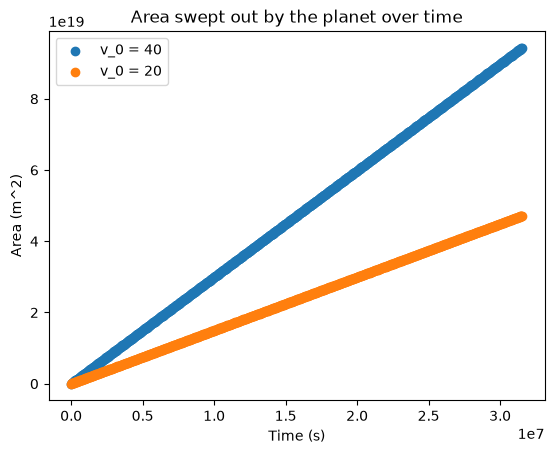

In [ ]:
def calculate_area(r_k,r_k_plus_1):
    """Calculate area swept out by the planet between two positions"""
    return 0.5 * abs(r_k[0] * r_k_plus_1[1] - r_k_plus_1[0] * r_k[1])  # Cross-product = area of a triangle formed by the two position vectors


def calculate_total_area(t:float, orbital_position, dt:float)->float:
    """Calculate area swept out up to time t"""
    area = 0.0
    time = 0.0
    x_init = 0.0
    y_init = 0.0
    while time < t:
        if t - time < dt:
            dt = t - time
        
        x, y = orbital_position(time)
        area += calculate_area(np.array([x_init, y_init]), np.array([x, y]))
        
        x_init = x
        y_init = y
        time += dt
    return area
def area_swept_out(v_0,dt=60*60*12) -> float:
    """Calculate area swept out by the planet up to time t"""
    r = r_0
    v = v_0
    area_swept = [0]
    time = [0]
    for i in range(365 * 2):  # Simulate for 1 year, with a half-day time step
        r_next = next_r(r, v, dt)
        v_next = next_v(r, r_next, v, dt)
        
        added_area = calculate_area(r, r_next)

        area_swept.append(added_area+area_swept[-1])
        time.append(time[-1] + dt)

        r = r_next
        v = v_next
    return time, area_swept

times1,area_swept1 = area_swept_out(40,dt=60*60*12)
times2,area_swept2 = area_swept_out(20,dt=60*60*12)


plt.scatter(times1, area_swept1, label='v_0 = 40')
plt.scatter(times2, area_swept2, label='v_0 = 20')
plt.title("Area swept out by planet over time")
plt.xlabel("Time (s)")
plt.ylabel("Area (m^2)")
plt.legend()
plt.show()

